# Predicting Coral Reef Regimes from Human and Natural Influences
### Google Colab notebook — Stanford CS229 project reproduction

This notebook builds a multiclass classifier for coral reef regime types using human and environmental predictors. It follows the workflow described by Walecka, Murphy, and Cheng:

1. Load the dataset and inspect its schema.
2. Prepare features and regime labels.
3. Create an 80/20 stratified train/test split.
4. Compare Logistic Regression, RBF SVM, Decision Tree, Random Forest, and Gradient Boosting with 5-fold cross-validation.
5. Tune the Random Forest using training data only.
6. Evaluate the final model once on the held-out test set.
7. Plot a confusion matrix and PCA diagnostic.

**Reference target:** the paper reports about 0.70 micro-F1 for the Random Forest with engineered features. This is a target for comparison, not a guaranteed score.

**Important:** this notebook checks the actual column names before assuming a target. It uses median imputation as a robust initial implementation; to exactly reproduce the paper's special K-means imputation and all five named interactions, verify the original feature-engineering notebook and adapt the corresponding cell.

## 1. Get the dataset

The Stanford project repository is here: [Hawaii_RegimesPredictors](https://github.com/salliewalecka/Hawaii_RegimesPredictors).

Run the next cell to clone it. If GitHub access fails, download the repository ZIP from the link above, upload it to Colab, and extract it manually.

In [1]:
!git clone https://github.com/salliewalecka/Hawaii_RegimesPredictors.git

Cloning into 'Hawaii_RegimesPredictors'...
remote: Enumerating objects: 526, done.
remote: Total 526 (delta 0), reused 0 (delta 0), pack-reused 526 (from 1)
Receiving objects: 100% (526/526), 19.30 MiB | 13.46 MiB/s, done.
Resolving deltas: 100% (253/253), done.


## 2. Install and import libraries

In [2]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [3]:
from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import joblib

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)
print("Libraries loaded.")

Libraries loaded.


## 3. Find and load the data

This cell lists likely data files in the cloned repository. If more than one candidate appears, inspect the list and select the predictor file that contains the regime label and human/biophysical predictors.

In [4]:
repo = Path("/content/Hawaii_RegimesPredictors")
if not repo.exists():
    raise FileNotFoundError(
        "Repository not found. Run the clone cell above, or upload/extract the repository into /content/Hawaii_RegimesPredictors."
    )

data_candidates = [
    p for p in repo.rglob("*")
    if p.is_file() and p.suffix.lower() in {".csv", ".tsv", ".txt"}
    and ".git" not in p.parts
]
print(f"Found {len(data_candidates)} candidate data/text files:")
for i, p in enumerate(data_candidates):
    print(f"[{i}] {p.relative_to(repo)}")

# Prefer files with 'regime' and 'predict' in their path/name; otherwise use the first candidate.
preferred = [p for p in data_candidates if "regime" in str(p).lower() and "predict" in str(p).lower()]
if not preferred:
    preferred = [p for p in data_candidates if "regime" in str(p).lower()]
if not preferred:
    preferred = data_candidates

if not preferred:
    raise FileNotFoundError("No CSV/TSV/TXT files found. Upload the dataset manually and set DATA_PATH.")

DATA_PATH = preferred[0]
print("\nSelected:", DATA_PATH)

Found 16 candidate data/text files:
[0] Data/scale_1000.txt
[1] Data/Hawaii_RegimesPredictors.txt
[2] Data/scale_500.txt
[3] Data/scale_4000.txt
[4] Data/Hawaii_PredictorsCategories.txt
[5] Data/ModelPerf_Across_Scales.txt
[6] Data/scale_1500.txt
[7] Data/RelInfluence_Across_Scales.txt
[8] Data/scale_2500.txt
[9] Data/Hawaii_RegimesPredictors_complete.txt
[10] Data/Modeling/Predictors_raw_train.txt
[11] Data/Modeling/Predictors_complete_test.txt
[12] Data/Modeling/Predictors_complete_val.txt
[13] Data/Modeling/Predictors_raw_val.txt
[14] Data/Modeling/Predictors_complete_train.txt
[15] Data/Modeling/Predictors_raw_test.txt

Selected: /content/Hawaii_RegimesPredictors/Data/scale_1000.txt


If the automatically selected file is not the data table, set `DATA_PATH` manually in the next cell. The reader tries common separators.

In [5]:
# Optional: override the selected path, e.g.
# DATA_PATH = Path("/content/Hawaii_RegimesPredictors/Data/RegimesPredictors.txt")

def read_table(path):
    try:
        df = pd.read_csv(path, sep=None, engine="python", comment="#")
        if df.shape[1] == 1:
            df = pd.read_csv(path, sep="\t", comment="#")
        if df.shape[1] == 1:
            df = pd.read_csv(path, delim_whitespace=True, comment="#")
    except Exception:
        df = pd.read_csv(path, sep="\t", comment="#")
    df.columns = [str(c).strip() for c in df.columns]
    return df.dropna(axis=0, how="all")

df = read_table(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Shape: (394, 49)


,FID,FID_1,Depth,Complexity,Coral,CCA,Turf,Macro,Other,Grazers,...,SST_STD,WAV_ANOM_F,WAV_CLIM_M,Majority,Regime,Regime1,Regime2,Regime3,Regime4,Regime5
0,0,1,"4,9","11,59458536","11,46875","24,21875","50,4375","13,25","0,3125","57,65543564",...,"1,04164","0,119073","47,8143997",two_thirds,2,0,1,0,0,0
1,1,3,24,"16,59628904","8,026755858","9,364548468","70,56856189","9,364548468","0,334448127","16,30081981",...,"0,980896","0,078293","73,1305008",two_thirds,2,0,1,0,0,0
2,2,4,11,"10,79841648",10,"4,8","41,2","27,2","13,6","12,30231275",...,"1,04164","0,072919","82,0968018",two_thirds,2,0,1,0,0,0
3,3,5,"1,32","5,542863001","7,958333333","7,750000001","56,04166667","20,1875","3,9375","19,14043843",...,"1,04164","0,0736037","82,6747971",two_thirds,2,0,1,0,0,0
4,4,6,"2,6","7,884183933","9,932603356","15,03125","54,73978727","10,57685889","7,956824368","36,0031556",...,"1,04164","0,0775555","80,3835983",two_thirds,2,0,1,0,0,0



Columns:
['FID', 'FID_1', 'Depth', 'Complexity', 'Coral', 'CCA', 'Turf', 'Macro', 'Other', 'Grazers', 'Scrapers', 'Browsers', 'Predators', 'Secondary', 'Sedimentation', 'Effluent', 'New_Development', 'Habitat_Modification', 'Invasive_Algae', 'FishingTotal', 'Fishing_NonComm_Total', 'Fishing_Comm_Total', 'Fishing_Comm_Line', 'Fishing_Comm_Net', 'Fishing_Comm_Spear', 'Fishing_NonComm_Boat_Total', 'Fishing_NonComm_Boat_Line', 'Fishing_NonComm_Boat_Net', 'Fishing_NonComm_Boat_Spear', 'Fishing_NonComm_Shore_Total', 'Fishing_NonComm_Shore_Line', 'Fishing_NonComm_Shore_Net', 'Fishing_NonComm_Shore_Spear', 'CHL_ANOM_F', 'CHL_CLIM_M', 'PAR_CLIM_M', 'PAR_STD', 'SST_CLIM_M', 'SST_DHW_MA', 'SST_STD', 'WAV_ANOM_F', 'WAV_CLIM_M', 'Majority', 'Regime', 'Regime1', 'Regime2', 'Regime3', 'Regime4', 'Regime5']


## 4. Identify the target and prepare the feature table

The target is the regime label. The paper excludes regime 4 and low-confidence labels in the dataset preparation described by the original authors; use the provided prepared dataset if available. This notebook does not invent or reconstruct missing GMM confidence values.

In [6]:
def norm_name(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

TARGET_COLUMN = None  # Set to the exact column name if automatic detection fails.

def detect_target(frame, requested=None):
    if requested:
        matches = [c for c in frame.columns if norm_name(c) == norm_name(requested)]
        if matches:
            return matches[0]
        raise ValueError(f"Target {requested!r} not found. Columns: {frame.columns.tolist()}")
    names = {"regime", "regimeclass", "regimetype", "reefregime", "regimes", "class", "label", "target", "y"}
    matches = [c for c in frame.columns if norm_name(c) in names]
    if matches:
        return matches[0]
    for c in frame.columns:
        vals = frame[c].dropna().astype(str).str.strip()
        if 2 <= vals.nunique() <= 6 and vals.str.contains(r"(?i)regime").all():
            return c
    raise ValueError(
        "Could not automatically detect the regime-label column. Set TARGET_COLUMN to its exact name."
    )

target_col = detect_target(df, TARGET_COLUMN)
print("Target column:", target_col)
print("Target values/counts:")
display(df[target_col].value_counts(dropna=False).to_frame("count"))

Target column: Regime
Target values/counts:


,count
Regime,
2,118
1,113
3,72
5,67
0,24


In [7]:
y = df[target_col].astype(str).str.strip()
# Normalize labels like 'Regime 1' to '1' only when the transformation preserves distinct classes.
y_stripped = y.str.replace(r"(?i)^regime[\s_-]*", "", regex=True)
if y_stripped.nunique() == y.nunique():
    y = y_stripped

X = df.drop(columns=[target_col]).copy()

# Remove likely identifier / coordinate fields; keep ecological driver predictors.
id_pattern = re.compile(r"(^id$|site.?id|sample.?id|record.?id|latitude|longitude|^lat$|^lon$|^long$|geometry)", re.I)
drop_cols = [c for c in X.columns if id_pattern.search(str(c))]
X = X.drop(columns=drop_cols, errors="ignore")
X = X.dropna(axis=1, how="all")
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols, errors="ignore")

valid = y.notna() & y.ne("") & y.ne("nan")
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print(f"Rows: {len(X)} | predictors before encoding: {X.shape[1]} | classes: {sorted(y.unique().tolist())}")
print("Dropped likely ID/coordinate columns:", drop_cols or "None")
print("\nClass distribution:")
display(y.value_counts().sort_index().to_frame("count"))

Rows: 394 | predictors before encoding: 47 | classes: ['0', '1', '2', '3', '5']
Dropped likely ID/coordinate columns: None

Class distribution:


,count
Regime,
0,24
1,113
2,118
3,72
5,67


## 5. Train/test split

The paper used an 80/20 split (496 training and 124 test observations) and five-fold cross-validation on the training portion. Stratification keeps class proportions as similar as possible in both sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (315, 47) | Test: (79, 47)


## 6. Feature engineering

The paper describes five interactions:
- wave power × seafloor complexity
- wave power × depth
- seafloor complexity × depth
- invasive algae × irradiance
- wave anomaly × chlorophyll anomaly

Because dataset column names may vary, this cell finds matching columns by name and creates an interaction only when both variables are present. Inspect the printed list. If names do not match, adjust the mapping to the exact dataset columns.

In [9]:
def find_col(columns, term_groups):
    for terms in term_groups:
        terms = [norm_name(t) for t in terms]
        for c in columns:
            n = norm_name(c)
            if all(t in n for t in terms):
                return c
    return None

class ReefFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.columns_ = list(X.columns)
        definitions = [
            ("wave_power_x_complexity", [["wave", "power"]], [["complexity"]]),
            ("wave_power_x_depth", [["wave", "power"]], [["depth"]]),
            ("complexity_x_depth", [["complexity"]], [["depth"]]),
            ("invasive_algae_x_irradiance", [["invasive", "algae"], ["algae", "invasive"]], [["irradiance"]]),
            ("wave_anomaly_x_chlorophyll_anomaly", [["wave", "anomaly"]], [["chlorophyll", "anomaly"]]),
        ]
        self.interactions_ = []
        used = set()
        for new_name, left_terms, right_terms in definitions:
            left = find_col(self.columns_, left_terms)
            right = find_col(self.columns_, right_terms)
            if left and right and left != right and (left, right) not in used and (right, left) not in used:
                self.interactions_.append((new_name, left, right))
                used.add((left, right))
        return self

    def transform(self, X):
        out = X.copy()
        for new_name, left, right in self.interactions_:
            out[new_name] = pd.to_numeric(out[left], errors="coerce") * pd.to_numeric(out[right], errors="coerce")
        return out

feature_engineer = ReefFeatureEngineer()
X_train_fe = feature_engineer.fit_transform(X_train)
X_test_fe = feature_engineer.transform(X_test)

print("Interactions created:")
for item in feature_engineer.interactions_:
    print(" -", item[0], "=", item[1], "×", item[2])
if len(feature_engineer.interactions_) < 5:
    print("WARNING: fewer than five interactions matched. Check column names and adjust the definitions.")
print("Feature count:", X_train_fe.shape[1])

Interactions created:
 - complexity_x_depth = Complexity × Depth
Feature count: 48


## 7. Preprocessing and model comparison

Numerical predictors use median imputation and standardization; categorical predictors use most-frequent imputation and one-hot encoding. Preprocessing is inside each scikit-learn pipeline, so it is fitted separately within each cross-validation fold and avoids validation leakage.

This is a robust starting point, but it is not the paper's exact K-means imputation procedure.

In [10]:
def make_preprocessor(frame):
    numeric_cols = frame.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_cols = [c for c in frame.columns if c not in numeric_cols]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols),
    ])

preprocessor = make_preprocessor(X_train_fe)

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "SVM (RBF)": Pipeline([
        ("prep", preprocessor),
        ("model", SVC(kernel="rbf"))
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocessor),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocessor),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_fe, y_train, cv=cv, scoring="f1_micro", n_jobs=None)
    cv_rows.append({"Model": name, "CV micro-F1 mean": scores.mean(), "CV micro-F1 std": scores.std()})
    print(f"{name:22s}: {scores.mean():.4f} ± {scores.std():.4f}")

cv_results = pd.DataFrame(cv_rows).sort_values("CV micro-F1 mean", ascending=False).reset_index(drop=True)
display(cv_results)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Logistic Regression   : 1.0000 ± 0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


SVM (RBF)             : 1.0000 ± 0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


...

Random Forest         : 0.9302 ± 0.0238


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Gradient Boosting     : 1.0000 ± 0.0000


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,Model,CV micro-F1 mean,CV micro-F1 std
0,Logistic Regression,1.000000,0.000000
1,SVM (RBF),1.000000,0.000000
2,Decision Tree,1.000000,0.000000
3,Gradient Boosting,1.000000,0.000000
4,Random Forest,0.930159,0.023757


## 8. Tune the Random Forest

Hyperparameters are selected using only the training split and five-fold cross-validation. The test set remains untouched until the final evaluation.

In [11]:
rf_pipeline = models["Random Forest"]
param_grid = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_micro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)
rf_search.fit(X_train_fe, y_train)

best_rf = rf_search.best_estimator_
print("Best CV micro-F1:", round(rf_search.best_score_, 4))
print("Best parameters:")
print(rf_search.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Best CV micro-F1: 1.0
Best parameters:
{'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1}


## 9. Final test evaluation

This is the one-time evaluation on the held-out test split. For single-label multiclass classification, micro-F1 and accuracy have the same numerical value.

Test accuracy:   1.0000
Test micro-F1:   1.0000

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00        23
           2       1.00      1.00      1.00        24
           3       1.00      1.00      1.00        14
           5       1.00      1.00      1.00        13

    accuracy                           1.00        79
   macro avg       1.00      1.00      1.00        79
weighted avg       1.00      1.00      1.00        79



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['complexity_x_depth']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


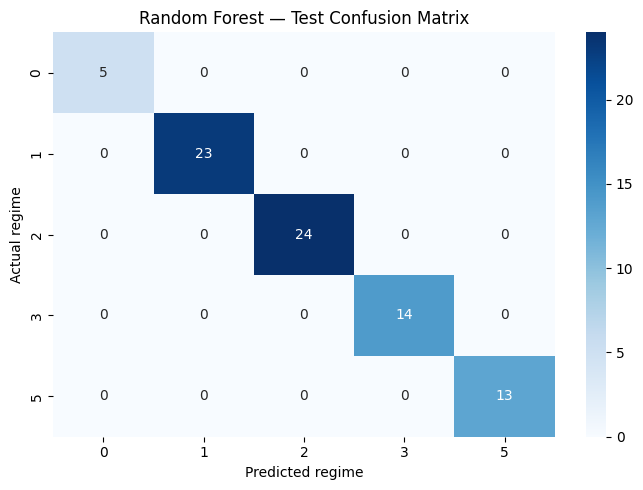

In [12]:
y_pred = best_rf.predict(X_test_fe)
test_micro_f1 = f1_score(y_test, y_pred, average="micro")
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy:   {test_accuracy:.4f}")
print(f"Test micro-F1:   {test_micro_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique(), key=lambda v: (not str(v).isdigit(), int(v) if str(v).isdigit() else str(v)))
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. PCA diagnostic

PCA is used here only to inspect how the numeric predictor data project into two dimensions. It is not used to train the classifier. Overlapping groups can help explain why the classes are difficult to separate, but a 2D plot cannot prove that classes are inseparable in the full feature space.

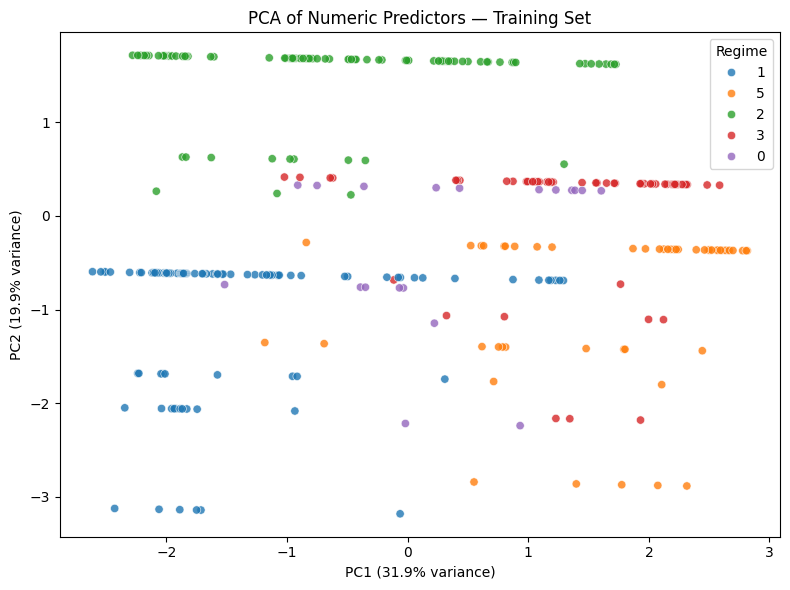

In [13]:
numeric_train = X_train_fe.select_dtypes(include=["number", "bool"]).copy()
if numeric_train.shape[1] >= 2:
    numeric_train = numeric_train.fillna(numeric_train.median()).fillna(0)
    scaled_numeric = StandardScaler().fit_transform(numeric_train)
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pcs = pca.fit_transform(scaled_numeric)

    pca_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "Regime": y_train.astype(str).values})
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Regime", alpha=0.8)
    plt.title("PCA of Numeric Predictors — Training Set")
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a 2-component PCA plot.")

## 11. Save the trained model and results

The saved bundle includes the fitted Random Forest pipeline, the feature engineer, and the input column names. Keep the feature columns and units consistent when making future predictions.

In [14]:
from pathlib import Path
import json

OUTPUT_DIR = Path("/content/coral_reef_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "feature_engineer": feature_engineer,
    "model": best_rf,
    "target_column": target_col,
    "input_columns": list(X.columns),
}, OUTPUT_DIR / "coral_reef_regime_model.joblib")

cv_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
plt.close()

summary = {
    "data_path": str(DATA_PATH),
    "target_column": target_col,
    "n_rows": int(len(X)),
    "n_predictors_before_encoding": int(X.shape[1]),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "classes": [str(c) for c in sorted(y.unique())],
    "best_cv_micro_f1": float(rf_search.best_score_),
    "test_micro_f1": float(test_micro_f1),
    "test_accuracy": float(test_accuracy),
    "paper_reference_test_micro_f1": 0.70,
    "random_state": RANDOM_STATE,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p)

Saved files:
 - /content/coral_reef_outputs/classification_report.csv
 - /content/coral_reef_outputs/confusion_matrix.png
 - /content/coral_reef_outputs/coral_reef_regime_model.joblib
 - /content/coral_reef_outputs/model_comparison.csv
 - /content/coral_reef_outputs/summary.json


## 12. Optional: download outputs

Run this cell to download the trained model and reports as one ZIP file.

In [15]:
import shutil
zip_path = shutil.make_archive("/content/coral_reef_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)

from google.colab import files
files.download(zip_path)

Created: /content/coral_reef_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>